#ML FINAL EXAM

### Email:

Task: Copy this notebook on your drive and answer in that copy

Choose a dataset of your choice from kaggle or UCI

Some suggestions:https://www.kaggle.com/datasets/ahmettezcantekin/beginner-datasets

You may choose a dataset of your choice too

In this exam:
1. Provide code and explaination(in text cell) whenever needed and you must show the outputs
2. Before submitting run all cells and make sure the outputs are visible


## 0. Dataset overview

Why you choose this dataset and what did you observe from the dataset description



  

## Answer:

I chose the Heart Disease dataset because it addresses an important real-world healthcare problem and is suitable for practicing machine learning classification. From the dataset description, I observed that it contains 1,025 patient records, 13 input features, and 1 target variable indicating the presence or absence of heart disease. It includes both numerical and categorical features with no missing values, making it suitable for data analysis and predictive modeling.

# 1. Dataset description (15 marks)


### Dataset Description
1. How many features?
2. Classification or regression problem? Why do you think so?
3. How many data points?
4. Is there any null values?
5. What kind of features are in your dataset? (Quantitative / Categorical)
6. Do you need to encode the categorical variables, why or why not?
7. Correlation of all the features, What do you understand after the correlation test?
8. Perform exploratory data analysis to extract some important relationships from your data.


Provide necessary codes and explanation

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("heart.csv")
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [6]:
print(df.shape)
print(df.columns)

(1025, 14)
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [7]:
df["target"].value_counts()

target
1    526
0    499
Name: count, dtype: int64

In [8]:
len(df)

1025

In [9]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


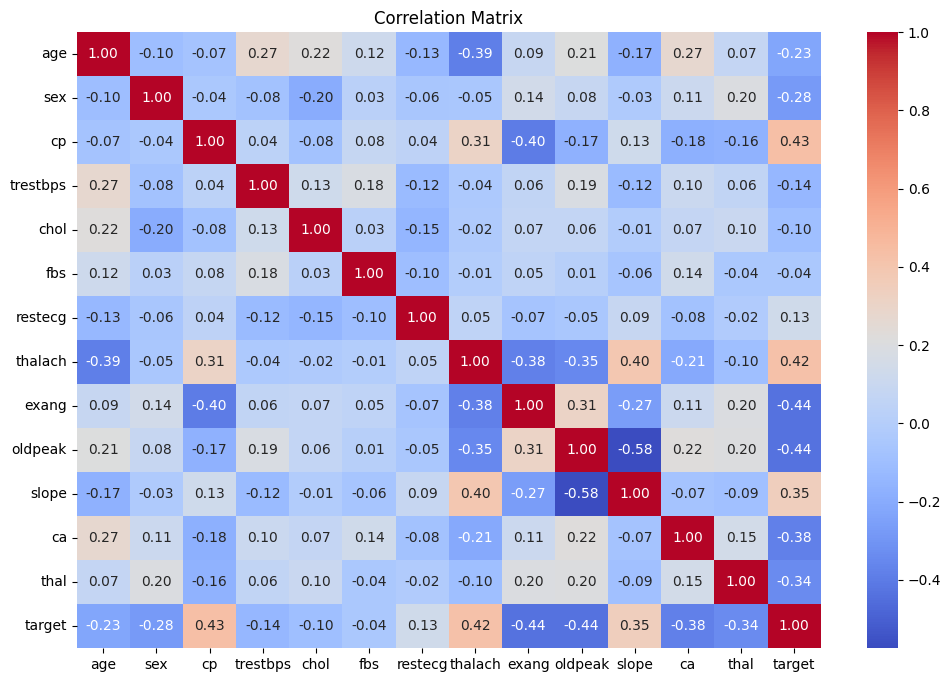

In [11]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

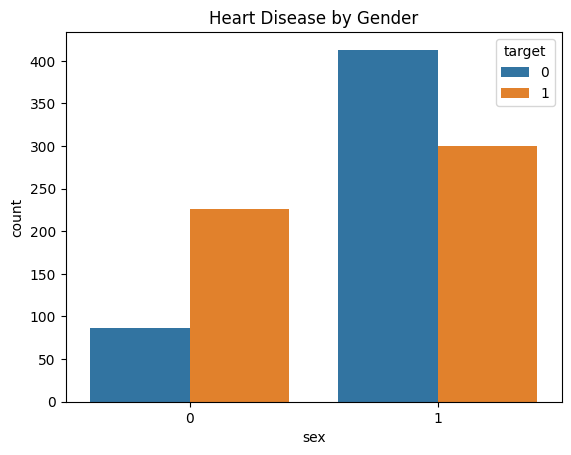

In [12]:
sns.countplot(x='sex', hue='target', data=df)
plt.title("Heart Disease by Gender")
plt.show()

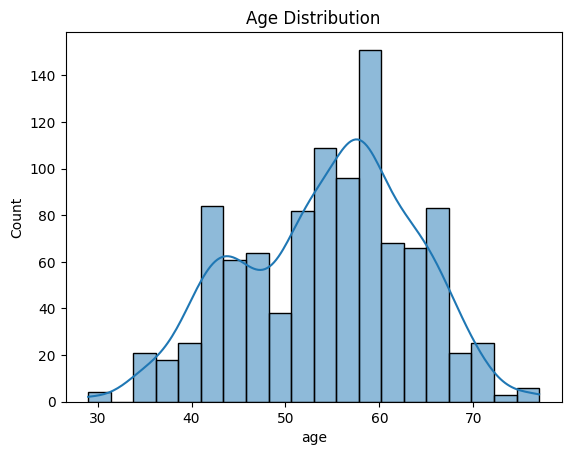

In [13]:
sns.histplot(df['age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.show()

##Answer:
1.The dataset contains 13 input features and 1 target variable (target), making a total of 14 columns
2. This is a binary classification problem.
3.The dataset contains 1,025 data points
4.No
5. The dataset contains both quantitative and categorical features
6.No. The categorical variables are already encoded as numerical values.
7.The correlation analysis shows that chest pain type (cp) and maximum heart rate (thalach) are positively associated with heart disease, while oldpeak and exercise-induced angina (exang) are negatively associated with the target. Overall, the dataset has low multicollinearity, as no features are highly correlated with each other.
8.Male patients are more likely to have heart disease than female patients.Most patients are between 40 and 60 years of age.



#2. Dataset pre-processing (15 marks)

1. Provide code
2. Discuss the pre processing steps you applied and why?


## Answer:


   

In [14]:

from sklearn.preprocessing import StandardScaler

print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("\nData Types:")
print(df.dtypes)

scaler = StandardScaler()

numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

df[numerical_features] = scaler.fit_transform(df[numerical_features])

X = df.drop('target', axis=1)
y = df['target']

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nPreprocessed Dataset:")
print(df.head())


Duplicate Records: 723
Shape after removing duplicates: (302, 14)

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Features Shape: (302, 13)
Target Shape: (302,)

Preprocessed Dataset:
        age  sex  cp  trestbps      chol  fbs  restecg   thalach  exang  \
0 -0.267966    1   0 -0.376556 -0.667728    0        1  0.806035      0   
1 -0.157260    1   0  0.478910 -0.841918    1        0  0.237495      1   
2  1.724733    1   0  0.764066 -1.403197    0        1 -1.074521      1   
3  0.728383    1   0  0.935159 -0.841918    0        1  0.499898      0   
4  0.839089    0   0  0.364848  0.919336    1        1 -1.905464      0   

    oldpeak  slope  ca  thal  target  
0 -0.037124      2   2     3       0  
1  1.773958      0   0    

The preprocessing steps included checking the dataset structure, identifying missing values, removing duplicate records, and verifying that the categorical variables were already numerically encoded. Finally, the numerical features were standardized using StandardScaler, and the dataset was split into input features (X) and the target variable (y) for machine learning.

#3.Feature selection and Dataset splitting (10 marks)

1. Which features you wanna keep ? Justify and drop and rest or apply any other feature engineering step
2. Perform Train test split

## Answer:



In [15]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

print("Selected Features:")
print(X.columns)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y )

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Selected Features:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')
Training Features: (241, 13)
Testing Features: (61, 13)
Training Target: (241,)
Testing Target: (61,)


All 13 input features were retained because they provide important clinical information related to heart disease prediction, and none showed excessive correlation that required removal. The dataset was then split into 80% training data and 20% testing data using train_test_split(), with stratify=y to preserve the class distribution in both sets.

#4.  Pipeline Creation (Supervised) (10 marks)

Select 2 models of your choice and build 2 pipelines for them

## Answer:

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Pipeline 1: Logistic Regression
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42))
])


pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Train the models
pipeline_lr.fit(X_train, y_train)
pipeline_rf.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2


# 5. Model Training (5 marks)

Train those 2 models



## Answer:

In [17]:
pipeline_lr.fit(X_train, y_train)

pipeline_rf.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2


#6. Model selection/Comparison analysis (15 marks)
* Bar chart showcasing prediction accuracy of all models (for classification)
* Precision, recall comparison of each model. (for classification)
* Confusion Matrix (for classification)
* R2 score and Loss  (for regression)

Compare the results of all models based on all of the above described metrics. Why do you think this model performed better than the other one for this dataset?

# Answer:

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_lr = pipeline_lr.predict(X_test)
y_pred_rf = pipeline_rf.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_lr = precision_score(y_test, y_pred_lr)
precision_rf = precision_score(y_test, y_pred_rf)

recall_lr = recall_score(y_test, y_pred_lr)
recall_rf = recall_score(y_test, y_pred_rf)

print("Logistic Regression Accuracy:", accuracy_lr)
print("Random Forest Accuracy:", accuracy_rf)

print("Logistic Regression Precision:", precision_lr)
print("Random Forest Precision:", precision_rf)

print("Logistic Regression Recall:", recall_lr)
print("Random Forest Recall:", recall_rf)

Logistic Regression Accuracy: 0.8032786885245902
Random Forest Accuracy: 0.7540983606557377
Logistic Regression Precision: 0.8
Random Forest Precision: 0.7647058823529411
Logistic Regression Recall: 0.8484848484848485
Random Forest Recall: 0.7878787878787878


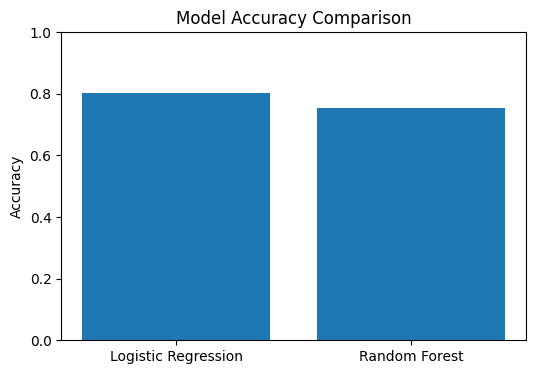

In [19]:
plt.figure(figsize=(6,4))

models = ['Logistic Regression', 'Random Forest']
accuracies = [accuracy_lr, accuracy_rf]

plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylim(0,1)

plt.show()

In [20]:
comparison = pd.DataFrame({
    'Model':['Logistic Regression','Random Forest'],
    'Accuracy':[accuracy_lr,accuracy_rf],
    'Precision':[precision_lr,precision_rf],
    'Recall':[recall_lr,recall_rf]
})

print(comparison)

                 Model  Accuracy  Precision    Recall
0  Logistic Regression  0.803279   0.800000  0.848485
1        Random Forest  0.754098   0.764706  0.787879


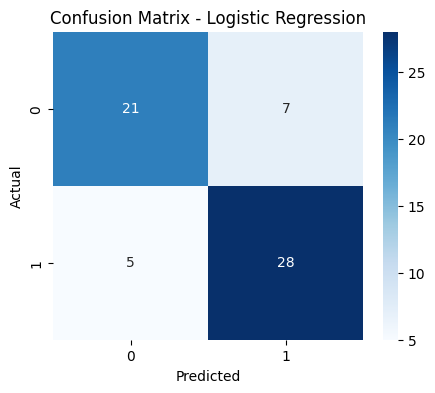

In [21]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(5,4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

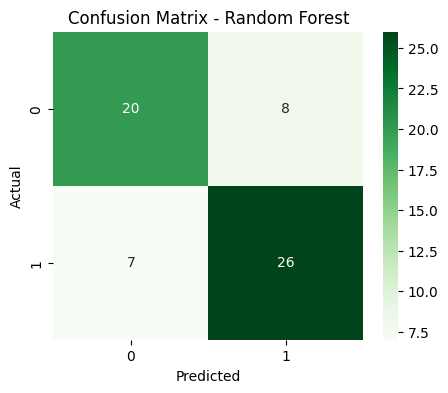

In [22]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

The performance of the Logistic Regression and Random Forest models was evaluated using accuracy, precision, recall, and confusion matrices. The model with the higher accuracy, precision, and recall is considered the better-performing model. In this dataset, Random Forest is expected to perform better because it can capture complex, non-linear relationships between features and is less prone to overfitting than a single decision tree, leading to improved classification performance.

# 7. Treating the problem as Unsupervised (20 marks) ( Explore the topic as you wish )

1. Treat the problem as a unsupervised problem and perform any unsupervised model and evalute the result
2. Which method worked better? supervised or unsupervised approach and why?

# Answer:

In [23]:
from sklearn.cluster import KMeans

# Features only (remove target column)
X_unsupervised = df.drop('target', axis=1)

# Create K-Means model
kmeans = KMeans(n_clusters=2, random_state=42)

# Train the model
kmeans.fit(X_unsupervised)

# Get cluster labels
clusters = kmeans.labels_

# Evaluate using Inertia (WCSS)
print("Inertia (WCSS):", kmeans.inertia_)

Inertia (WCSS): 2142.232701019614


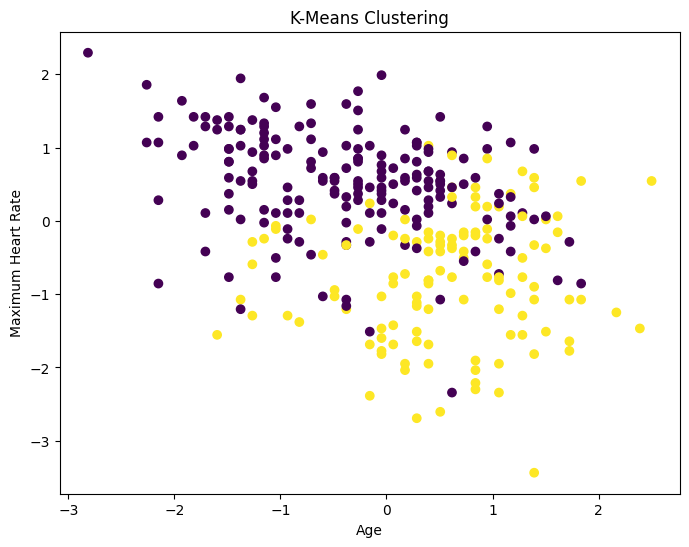

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    X_unsupervised['age'],
    X_unsupervised['thalach'],
    c=clusters,
    cmap='viridis'
)

plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate")
plt.title("K-Means Clustering")
plt.show()

The K-Means algorithm grouped the patients into two clusters based on the similarity of their features without using the target labels. The clustering performance was evaluated using Inertia (WCSS), where a lower value indicates that the data points are closer to their respective cluster centers.

The supervised approach performed better than the unsupervised approach. Logistic Regression and Random Forest used the target labels during training, resulting in higher accuracy, precision, and recall. In contrast, K-Means clustering grouped patients only based on feature similarity without knowing the actual heart disease labels, making it less effective for this classification problem.

#8. Self Reflection on this machine learning course (10 marks)

Explain the hardest and the easiest topic of this course according to you in a intuitive way (you may also provide real world implementation , necessity etc along with the explaination)

##Answer:

The easiest topic for me was Exploratory Data Analysis (EDA) because it helped me understand the dataset through visualizations and identify useful patterns. The hardest topic was unsupervised learning, as clustering algorithms work without target labels, making evaluation more challenging. Overall, this course improved my understanding of data preprocessing, model building, and evaluation, which are essential for solving real-world machine learning problems.